In [1]:
import sys
print(sys.executable)

/home/piets/sirna_shrna_offtargets/.venv/bin/python


In [2]:
import pandas as pd
from pathlib import Path

print("All imports successful")

All imports successful


In [3]:
# Load raw count data and gene_mapping dataframe to start

# File paths
raw_path = Path(
    "../data/raw/GSE114273 (siPARP1_siPARP2)/GSE114273_raw_counts_GRCh38.p13_NCBI.tsv.gz"
)

mapping_path = Path(
    "../data/processed/GSE114273 (siPARP1_siPARP2)/GSE114273_gene_mapping_protein_coding.tsv"
)

# Load data
raw_counts = pd.read_csv(raw_path, sep="\t")
gene_mapping = pd.read_csv(mapping_path, sep="\t")

In [ ]:
# Inspect

print("Raw counts shape:", raw_counts.shape)
print('Raw counts data:', raw_counts.dtypes.value_counts()) #PyDESeq2 wants integers
print("Gene mapping shape:", gene_mapping.shape)

print("\nRaw count columns:")
print(raw_counts.columns.tolist())

display(raw_counts.head())
display(gene_mapping.head())

Raw counts shape: (39376, 19)
Raw counts data: int64    19
Name: count, dtype: int64
Gene mapping shape: (19227, 5)

Raw count columns:
['GeneID', 'GSM3138699', 'GSM3138700', 'GSM3138701', 'GSM3138702', 'GSM3138703', 'GSM3138704', 'GSM3138705', 'GSM3138706', 'GSM3138707', 'GSM3138708', 'GSM3138709', 'GSM3138710', 'GSM3138711', 'GSM3138712', 'GSM3138713', 'GSM3138714', 'GSM3138715', 'GSM3138716']


,GeneID,GSM3138699,GSM3138700,GSM3138701,GSM3138702,GSM3138703,GSM3138704,GSM3138705,GSM3138706,GSM3138707,GSM3138708,GSM3138709,GSM3138710,GSM3138711,GSM3138712,GSM3138713,GSM3138714,GSM3138715,GSM3138716
0,100287102,5,8,6,5,5,5,5,4,1,1,1,1,1,0,1,1,1,1
1,653635,314,385,386,413,351,356,249,263,79,91,97,77,86,64,79,77,98,101
2,102466751,11,8,16,14,14,10,9,9,2,1,1,2,2,2,2,1,3,2
3,107985730,2,1,1,1,2,1,0,2,1,0,0,0,0,0,0,0,0,0
4,100302278,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


,GeneID,EnsemblGeneID,Symbol,GeneType,Description
0,79501,ENSG00000186092,OR4F5,protein-coding,olfactory receptor family 4 subfamily F member 5
1,729759,ENSG00000284733,OR4F29,protein-coding,olfactory receptor family 4 subfamily F member 29
2,81399,ENSG00000284662,OR4F16,protein-coding,olfactory receptor family 4 subfamily F member 16
3,148398,ENSG00000187634,SAMD11,protein-coding,sterile alpha motif domain containing 11
4,26155,ENSG00000188976,NOC2L,protein-coding,NOC2 like nucleolar associated transcriptional...


In [4]:
# Isolate ten samples of interest

selected_samples = [
    f"GSM{i}" for i in range(3138707, 3138717)
]

raw_counts_selected = raw_counts[
    ["GeneID"] + selected_samples
].copy()

In [5]:
# Rename samples for clarity

sample_labels = {
    "GSM3138707": "siNC_rep1",
    "GSM3138708": "siNC_rep2",
    "GSM3138709": "siPARP1-A_rep1",
    "GSM3138710": "siPARP1-A_rep2",
    "GSM3138711": "siPARP1-B_rep1",
    "GSM3138712": "siPARP1-B_rep2",
    "GSM3138713": "siPARP2-A_rep1",
    "GSM3138714": "siPARP2-A_rep2",
    "GSM3138715": "siPARP2-B_rep1",
    "GSM3138716": "siPARP2-B_rep2"
}

raw_counts_selected = raw_counts_selected.rename(
    columns=sample_labels
)

In [6]:
# Define sample groups for analysis

sample_groups = {
    "siNC": ["siNC_rep1", "siNC_rep2"],
    "siPARP1-A": ["siPARP1-A_rep1", "siPARP1-A_rep2"],
    "siPARP1-B": ["siPARP1-B_rep1", "siPARP1-B_rep2"],
    "siPARP2-A": ["siPARP2-A_rep1", "siPARP2-A_rep2"],
    "siPARP2-B": ["siPARP2-B_rep1", "siPARP2-B_rep2"]
}

# Inspect

print("Shape:", raw_counts_selected.shape)
display(raw_counts_selected.head())

Shape: (39376, 11)


,GeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
0,100287102,1,1,1,1,1,0,1,1,1,1
1,653635,79,91,97,77,86,64,79,77,98,101
2,102466751,2,1,1,2,2,2,2,1,3,2
3,107985730,1,0,0,0,0,0,0,0,0,0
4,100302278,0,0,0,0,0,0,0,0,0,0


In [8]:
# Merge dataframes

deseq2_data = gene_mapping[
    ["GeneID", "EnsemblGeneID"]
].merge(
    raw_counts_selected,
    on="GeneID",
    how="inner"
)

In [12]:
# Inspect

print("Shape:", deseq2_data.shape)
print("Unique GeneIDs:", deseq2_data["GeneID"].nunique())
print("Unique Ensembl IDs:", deseq2_data["EnsemblGeneID"].nunique())

print("\nMissing values:")
print(deseq2_data.isna().sum())

print("\nCount data types:")
print(deseq2_data[sample_groups["siNC"]].dtypes)
display(deseq2_data.head())

Shape: (19227, 12)
Unique GeneIDs: 19227
Unique Ensembl IDs: 19227

Missing values:
GeneID            0
EnsemblGeneID     0
siNC_rep1         0
siNC_rep2         0
siPARP1-A_rep1    0
siPARP1-A_rep2    0
siPARP1-B_rep1    0
siPARP1-B_rep2    0
siPARP2-A_rep1    0
siPARP2-A_rep2    0
siPARP2-B_rep1    0
siPARP2-B_rep2    0
dtype: int64

Count data types:
siNC_rep1    int64
siNC_rep2    int64
dtype: object


,GeneID,EnsemblGeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
0,79501,ENSG00000186092,0,0,0,0,0,0,0,0,0,0
1,729759,ENSG00000284733,0,0,1,0,0,0,0,0,1,0
2,81399,ENSG00000284662,1,2,2,1,1,1,2,2,1,2
3,148398,ENSG00000187634,481,571,402,351,545,504,506,479,283,367
4,26155,ENSG00000188976,2411,2888,2814,2607,2585,2229,3944,3791,2949,3375


In [10]:
count_columns = [
    sample
    for samples in sample_groups.values()
    for sample in samples
]

print(
    "All counts are non-negative integers:",
    (deseq2_data[count_columns].ge(0).all().all()
     and (deseq2_data[count_columns] % 1 == 0).all().all())
)

All counts are non-negative integers: True


In [14]:
# Save merged dataframe 

output_path = Path(
    "../data/processed/GSE114273 (siPARP1_siPARP2)/GSE114273_mapped_raw_merged.tsv"
)

deseq2_data.to_csv(output_path, sep="\t", index=False)

In [ ]:
# Load checkpoint

In [18]:
# Generate count matrix from deseq2_data df

count_matrix = deseq2_data.set_index("EnsemblGeneID")[count_columns]

In [20]:
# Inspect 

print("Shape:", count_matrix.shape)
print("Unique genes:", count_matrix.index.nunique()) # Check for duplicates
display(count_matrix.head())

Shape: (19227, 10)
Unique genes: 19227


,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
EnsemblGeneID,,,,,,,,,,
ENSG00000186092,0,0,0,0,0,0,0,0,0,0
ENSG00000284733,0,0,1,0,0,0,0,0,1,0
ENSG00000284662,1,2,2,1,1,1,2,2,1,2
ENSG00000187634,481,571,402,351,545,504,506,479,283,367
ENSG00000188976,2411,2888,2814,2607,2585,2229,3944,3791,2949,3375


In [22]:
# Create a metadata DataFrame describing the treatment assigned to each sample (needed for PyDESeq2)

metadata_df = pd.DataFrame({
    "sample_ID": count_matrix.columns,
    "condition": [
        "siNC", "siNC",
        "siPARP1-A", "siPARP1-A",
        "siPARP1-B", "siPARP1-B",
        "siPARP2-A", "siPARP2-A",
        "siPARP2-B", "siPARP2-B"
    ]
})

metadata_df = metadata_df.set_index("sample_ID")

display(metadata_df)

,condition
sample_ID,
siNC_rep1,siNC
siNC_rep2,siNC
siPARP1-A_rep1,siPARP1-A
siPARP1-A_rep2,siPARP1-A
siPARP1-B_rep1,siPARP1-B
siPARP1-B_rep2,siPARP1-B
siPARP2-A_rep1,siPARP2-A
siPARP2-A_rep2,siPARP2-A
siPARP2-B_rep1,siPARP2-B


In [24]:
# Transpose count_matrix to align with metadata_df

counts = count_matrix.T.copy()

metadata = metadata_df.loc[counts.index].copy()

In [25]:
# Validate alignment

print("Counts shape:", counts.shape)
print("Metadata shape:", metadata.shape)

print("Sample order matches:",
      counts.index.equals(metadata.index))

display(metadata)

Counts shape: (10, 19227)
Metadata shape: (10, 1)
Sample order matches: True


,condition
sample_ID,
siNC_rep1,siNC
siNC_rep2,siNC
siPARP1-A_rep1,siPARP1-A
siPARP1-A_rep2,siPARP1-A
siPARP1-B_rep1,siPARP1-B
siPARP1-B_rep2,siPARP1-B
siPARP2-A_rep1,siPARP2-A
siPARP2-A_rep2,siPARP2-A
siPARP2-B_rep1,siPARP2-B


In [28]:
# Set siNC as reference

metadata["condition"] = pd.Categorical(
    metadata["condition"],
    categories=[
        "siNC",
        "siPARP1-A",
        "siPARP1-B",
        "siPARP2-A",
        "siPARP2-B"
    ]
)

In [29]:
# Create PyDESeq2 Dataset

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

dds = DeseqDataSet(
    counts=counts,
    metadata=metadata,
    design="~ condition",
    refit_cooks=True,
    n_cpus=4
)

#### Dataset

counts: raw counts, with samples as rows.

metadata: sample information, indexed by sample IDs.

design: tells PyDESeq2 which variables to include in the model.

refit_cooks: enables refitting for certain outlier observations.

In [30]:
print(dds)
print("\nDesign factors:", dds.obsm["design_matrix"].columns.tolist())
print("\nCount matrix shape:", dds.X.shape)

AnnData object with n_obs × n_vars = 10 × 19227
    obs: 'condition'
    obsm: 'design_matrix'
    layers: None (.X)

Design factors: ['Intercept', 'condition[T.siPARP1-A]', 'condition[T.siPARP1-B]', 'condition[T.siPARP2-A]', 'condition[T.siPARP2-B]']

Count matrix shape: (10, 19227)


In [31]:
# Estimate size factors to account for technical variability

dds.fit_size_factors()

print(dds.obs[["size_factors"]] if "size_factors" in dds.obs.columns else dds.obsm)

Using None as control genes, passed at DeseqDataSet initialization
                size_factors
sample_ID                   
siNC_rep1           0.975285
siNC_rep2           1.103425
siPARP1-A_rep1      1.031625
siPARP1-A_rep2      0.981676
siPARP1-B_rep1      0.922423
siPARP1-B_rep2      0.899829
siPARP2-A_rep1      1.021910
siPARP2-A_rep2      1.011247
siPARP2-B_rep1      1.047026
siPARP2-B_rep2      1.121477


Fitting size factors...
... done in 0.02 seconds.



In [32]:
# Estimate dispersion parameter (accounting for biological and residual variability)

dds.fit_genewise_dispersions()

Fitting dispersions...
... done in 2.52 seconds.



In [34]:
# Inspect dispersions

dispersions = dds.var['genewise_dispersions']

print(dispersions.describe())

count    1.724000e+04
mean     4.626603e-02
std      6.248107e-01
min      1.000000e-08
25%      1.000000e-08
50%      1.000000e-08
75%      1.186255e-03
max      1.000000e+01
Name: genewise_dispersions, dtype: float64


In [35]:
print("Total genes:", dds.n_vars)
print("Genes with dispersion estimates:", dispersions.notna().sum())
print("Genes without estimates:", dispersions.isna().sum())

Total genes: 19227
Genes with dispersion estimates: 17240
Genes without estimates: 1987


In [36]:
# Fit dispersion trend (describe how dispersion relates to mean exp. - low expressed genes tend to disperse more than highly expressed ones)

dds.fit_dispersion_trend()

Fitting dispersion trend curve...
... done in 0.28 seconds.



In [37]:
# Inspect fitted dispersion trend

print("Dispersion function type:", dds.uns["disp_function_type"])
print("Trend coefficients:", dds.uns["trend_coeffs"])

print("\nFitted dispersion summary:")
print(dds.var["fitted_dispersions"].describe())

Dispersion function type: parametric
Trend coefficients: a0    0.001312
a1    1.772628
dtype: float64

Fitted dispersion summary:
count    17240.000000
mean         1.396482
std          3.920092
min          0.001319
25%          0.003215
50%          0.009660
75%          0.277217
max         19.880933
Name: fitted_dispersions, dtype: float64


In [38]:
# Dispersion shrinkage

dds.fit_dispersion_prior()
dds.fit_MAP_dispersions()

Fitting MAP dispersions...
... done in 3.56 seconds.



In [39]:
# Inspect 

dispersion_comparison = dds.var[
    [
        "genewise_dispersions",
        "fitted_dispersions",
        "dispersions"
    ]
]

display(dispersion_comparison.describe())

,genewise_dispersions,fitted_dispersions,dispersions
count,1.724000e+04,17240.000000,1.724000e+04
mean,4.626603e-02,1.396482,1.129544e+00
std,6.248107e-01,3.920092,2.774501e+00
min,1.000000e-08,0.001319,1.045403e-08
25%,1.000000e-08,0.003215,2.853120e-03
50%,1.000000e-08,0.009660,8.481250e-03
75%,1.186255e-03,0.277217,2.225769e-01
max,1.000000e+01,19.880933,1.000000e+01


In [40]:
# Fit the model

dds.fit_LFC()

Fitting LFCs...
... done in 2.74 seconds.



In [41]:
# assess whether individual samples have an unusually large influence on the estimated results

dds.calculate_cooks()

Calculating cook's distance...
... done in 0.02 seconds.



In [42]:
dds.refit()

Replacing 0 outlier genes.



In [43]:
from pydeseq2.ds import DeseqStats

contrasts = [
    "siPARP1-A",
    "siPARP1-B",
    "siPARP2-A",
    "siPARP2-B"
]

stat_results = {}

for treatment in contrasts:
    stat_res = DeseqStats(
        dds,
        contrast=["condition", treatment, "siNC"],
        n_cpus=4
    )
    stat_res.summary()
    stat_results[treatment] = stat_res.results_df


Running Wald tests...


... done in 3.41 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition siPARP1-A vs siNC
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000             NaN       NaN       NaN       NaN   
ENSG00000284733     0.192443        1.476045  5.345056  0.276151  0.782432   
ENSG00000284662     1.466398        0.053289  1.747147  0.030501  0.975668   
ENSG00000187634   447.519945       -0.435754  0.119166 -3.656705  0.000255   
ENSG00000188976  2918.659251        0.080683  0.069533  1.160357  0.245903   
...                      ...             ...       ...       ...       ...   
ENSG00000205916     0.184677        0.043792  5.668402  0.007726  0.993836   
ENSG00000185894     0.096934        1.476054  5.345060  0.276153  0.782431   
ENSG00000172288     0.189515       -1.373261  5.347134 -0.256822  0.797316   
ENSG00000276256   148.984079       -0.350182  0.185472 -1.888060  0.059018  

... done in 1.03 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition siPARP1-B vs siNC
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000             NaN       NaN       NaN       NaN   
ENSG00000284733     0.192443        0.187296  5.668367  0.033042  0.973641   
ENSG00000284662     1.466398       -0.381726  1.842902 -0.207133  0.835906   
ENSG00000187634   447.519945        0.187013  0.115837  1.614445  0.106431   
ENSG00000188976  2918.659251        0.052696  0.069880  0.754091  0.450794   
...                      ...             ...       ...       ...       ...   
ENSG00000205916     0.184677        0.187299  5.668368  0.033043  0.973640   
ENSG00000185894     0.096934        0.187305  5.668370  0.033044  0.973640   
ENSG00000172288     0.189515       -1.229754  5.347098 -0.229985  0.818103   
ENSG00000276256   148.984079        0.132018  0.181102  0.728969  0.466021  

... done in 1.08 seconds.

Running Wald tests...


Log2 fold change & Wald test p-value: condition siPARP2-A vs siNC
                    baseMean  log2FoldChange     lfcSE      stat  \
EnsemblGeneID                                                      
ENSG00000186092     0.000000             NaN       NaN       NaN   
ENSG00000284733     0.192443        0.029207  5.668358  0.005153   
ENSG00000284662     1.466398        0.460201  1.695862  0.271367   
ENSG00000187634   447.519945       -0.061585  0.116390 -0.529121   
ENSG00000188976  2918.659251        0.579673  0.068700  8.437743   
...                      ...             ...       ...       ...   
ENSG00000205916     0.184677        0.029210  5.668359  0.005153   
ENSG00000185894     0.096934        0.029216  5.668361  0.005154   
ENSG00000172288     0.189515        0.060253  5.000739  0.012049   
ENSG00000276256   148.984079       -0.232606  0.183656 -1.266533   
ENSG00000277630     0.199469       -1.477784  5.335093 -0.276993   

                       pvalue          padj  
Ens

... done in 1.03 seconds.



In [23]:
# Inspect 

results_df = stat_res.results_df.copy()

print("Shape:", results_df.shape)

print("\nMissing adjusted p-values:", results_df["padj"].isna().sum())

print("\nSignificant genes (padj < 0.05):",
      (results_df["padj"] < 0.05).sum())

print("\nLog2FC distribution:")
print(results_df["log2FoldChange"].describe())

print("\nTop 10 genes by adjusted p-value:")
display(
    results_df.sort_values("padj").head(10)
)

Shape: (60676, 6)

Missing adjusted p-values: 54468

Significant genes (padj < 0.05): 97

Log2FC distribution:
count    28950.000000
mean        -0.041889
std          0.899951
min         -5.121926
25%         -0.306786
50%         -0.017797
75%          0.261443
max          4.680842
Name: log2FoldChange, dtype: float64

Top 10 genes by adjusted p-value:


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
ENSEMBL ID,,,,,,
ENSG00000138138,1529.598799,-0.799415,0.095022,-8.412983,3.997135e-17,2.481421e-13
ENSG00000117899,1173.057466,-0.715196,0.101609,-7.038724,1.940079e-12,6.022006e-09
ENSG00000051620,8312.392698,-0.222510,0.035679,-6.236427,4.476793e-10,7.358737e-07
ENSG00000166819,30470.281170,-0.449379,0.072161,-6.227431,4.741454e-10,7.358737e-07
ENSG00000152583,1018.126324,-0.677845,0.111592,-6.074327,1.245085e-09,1.545897e-06
ENSG00000186480,14038.469145,-0.353628,0.062132,-5.691562,1.258823e-08,1.302462e-05
ENSG00000113721,13720.322658,-0.403366,0.071527,-5.639374,1.706693e-08,1.513593e-05
ENSG00000197635,947.989489,0.660324,0.118696,5.563157,2.649373e-08,2.055914e-05
ENSG00000157150,3592.154061,-0.406404,0.073782,-5.508136,3.626540e-08,2.501506e-05


In [44]:
# Inspect each siRNA DGE

for treatment, results in stat_results.items():
    print(f"\n{treatment}")
    print("Shape:", results.shape)
    print(results.head())


siPARP1-A
Shape: (19227, 6)
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000             NaN       NaN       NaN       NaN   
ENSG00000284733     0.192443        1.476045  5.345056  0.276151  0.782432   
ENSG00000284662     1.466398        0.053289  1.747147  0.030501  0.975668   
ENSG00000187634   447.519945       -0.435754  0.119166 -3.656705  0.000255   
ENSG00000188976  2918.659251        0.080683  0.069533  1.160357  0.245903   

                     padj  
EnsemblGeneID              
ENSG00000186092       NaN  
ENSG00000284733       NaN  
ENSG00000284662       NaN  
ENSG00000187634  0.000951  
ENSG00000188976  0.371888  

siPARP1-B
Shape: (19227, 6)
                    baseMean  log2FoldChange     lfcSE      stat    pvalue  \
EnsemblGeneID                                                                
ENSG00000186092     0.000000             Na

In [45]:
for treatment, results in stat_results.items():
    print(f"\n{treatment}")
    print("Genes with valid log2FC:",
          results["log2FoldChange"].notna().sum())
    print("Significant genes (padj < 0.05):",
          (results["padj"] < 0.05).sum())
    print("Upregulated:",
          ((results["log2FoldChange"] > 0) &
           (results["padj"] < 0.05)).sum())
    print("Downregulated:",
          ((results["log2FoldChange"] < 0) &
           (results["padj"] < 0.05)).sum())


siPARP1-A
Genes with valid log2FC: 17240
Significant genes (padj < 0.05): 6029
Upregulated: 2917
Downregulated: 3112

siPARP1-B
Genes with valid log2FC: 17240
Significant genes (padj < 0.05): 3936
Upregulated: 1747
Downregulated: 2189

siPARP2-A
Genes with valid log2FC: 17240
Significant genes (padj < 0.05): 5431
Upregulated: 2768
Downregulated: 2663

siPARP2-B
Genes with valid log2FC: 17240
Significant genes (padj < 0.05): 7806
Upregulated: 3874
Downregulated: 3932


In [46]:
# Check PARP1 and PARP2 DGE for each siRNA

target_genes = {
    "PARP1": "ENSG00000143799",
    "PARP2": "ENSG00000129484"
}

target_results = []

for treatment, results in stat_results.items():
    for gene, ensembl_id in target_genes.items():

        row = results.loc[ensembl_id]

        target_results.append({
            "Gene": gene,
            "EnsemblGeneID": ensembl_id,
            "siRNA": treatment,
            "baseMean": row["baseMean"],
            "log2FoldChange": row["log2FoldChange"],
            "lfcSE": row["lfcSE"],
            "pvalue": row["pvalue"],
            "padj": row["padj"]
        })

target_results_df = pd.DataFrame(target_results)

display(target_results_df.round(4))

,Gene,EnsemblGeneID,siRNA,baseMean,log2FoldChange,lfcSE,pvalue,padj
0,PARP1,ENSG00000143799,siPARP1-A,3466.8514,-6.5181,0.1285,0.0000,0.0000
1,PARP2,ENSG00000129484,siPARP1-A,269.2471,-0.3321,0.1347,0.0137,0.0336
2,PARP1,ENSG00000143799,siPARP1-B,3466.8514,-5.6891,0.1092,0.0000,0.0000
3,PARP2,ENSG00000129484,siPARP1-B,269.2471,-0.4907,0.1369,0.0003,0.0020
4,PARP1,ENSG00000143799,siPARP2-A,3466.8514,-0.2086,0.0671,0.0019,0.0061
5,PARP2,ENSG00000129484,siPARP2-A,269.2471,-3.0524,0.1802,0.0000,0.0000
6,PARP1,ENSG00000143799,siPARP2-B,3466.8514,-1.5956,0.0687,0.0000,0.0000
7,PARP2,ENSG00000129484,siPARP2-B,269.2471,-4.1557,0.2228,0.0000,0.0000


In [47]:
# Save data

for treatment, results in stat_results.items():
    filename = f"GSE114273_{treatment}_DGE_results.tsv"

    results.to_csv(
        f"../data/processed/GSE114273 (siPARP1_siPARP2)/{filename}",
        sep="\t",
        index=True
    )

#### Visualization of DGE

In [ ]:
# Load checkpoint 


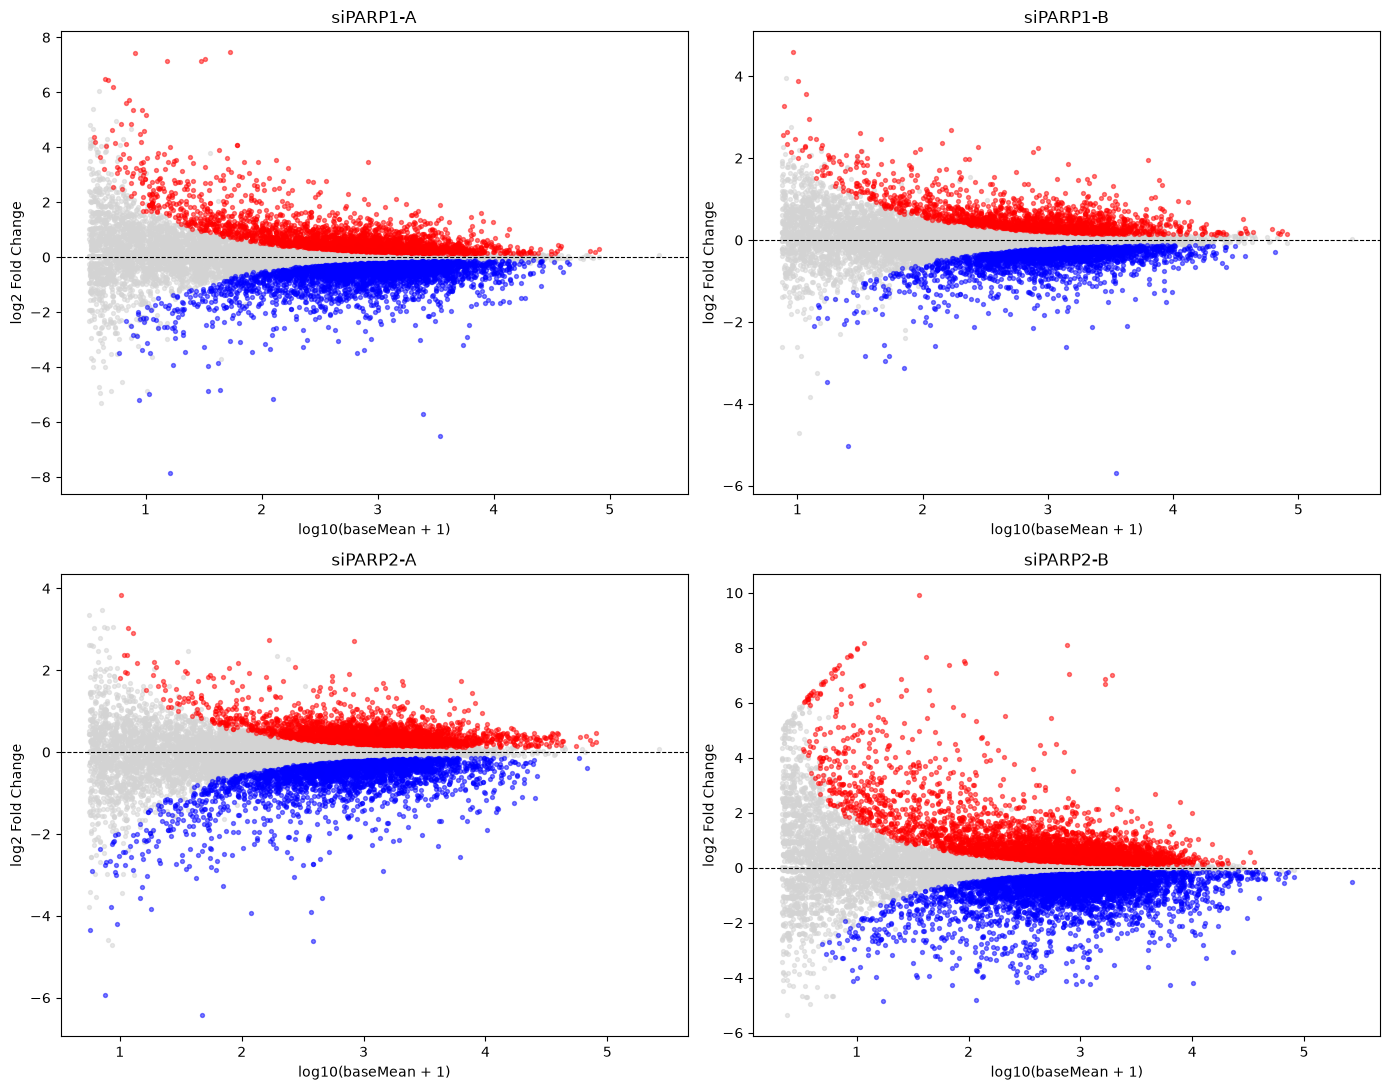

In [48]:
import matplotlib.pyplot as plt
import numpy as np

# MA plots 

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for ax, (treatment, results) in zip(axes, stat_results.items()):

    plot_data = results.dropna(
        subset=["baseMean", "log2FoldChange", "padj"]
    ).copy()

    significant = plot_data["padj"] < 0.05
    upregulated = significant & (plot_data["log2FoldChange"] > 0)
    downregulated = significant & (plot_data["log2FoldChange"] < 0)
    not_significant = ~significant

    ax.scatter(
        np.log10(plot_data.loc[not_significant, "baseMean"] + 1),
        plot_data.loc[not_significant, "log2FoldChange"],
        color="lightgrey", s=8, alpha=0.5
    )

    ax.scatter(
        np.log10(plot_data.loc[upregulated, "baseMean"] + 1),
        plot_data.loc[upregulated, "log2FoldChange"],
        color="red", s=8, alpha=0.5
    )

    ax.scatter(
        np.log10(plot_data.loc[downregulated, "baseMean"] + 1),
        plot_data.loc[downregulated, "log2FoldChange"],
        color="blue", s=8, alpha=0.5
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(treatment)
    ax.set_xlabel("log10(baseMean + 1)")
    ax.set_ylabel("log2 Fold Change")

plt.tight_layout()
plt.show()

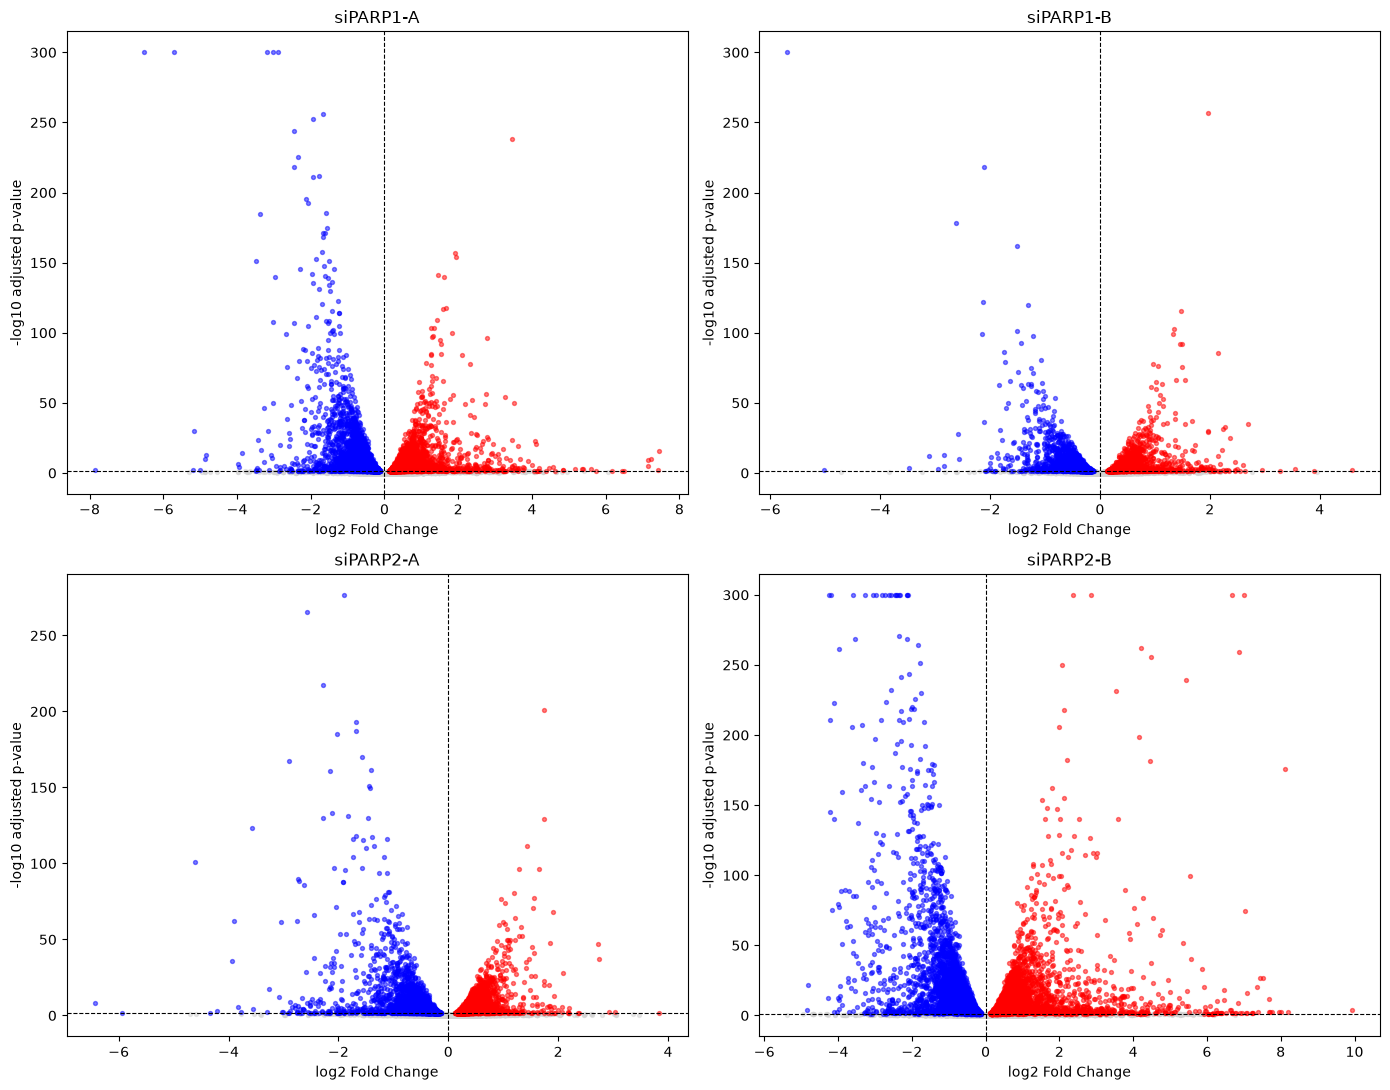

In [49]:
# Volcano plots

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for ax, (treatment, results) in zip(axes, stat_results.items()):

    plot_data = results.dropna(
        subset=["log2FoldChange", "padj"]
    ).copy()

    # Avoid log10(0)
    plot_data["neg_log10_padj"] = -np.log10(
        plot_data["padj"].clip(lower=1e-300)
    )

    significant = plot_data["padj"] < 0.05

    upregulated = significant & (plot_data["log2FoldChange"] > 0)
    downregulated = significant & (plot_data["log2FoldChange"] < 0)
    not_significant = ~significant

    ax.scatter(
        plot_data.loc[not_significant, "log2FoldChange"],
        plot_data.loc[not_significant, "neg_log10_padj"],
        color="lightgrey", s=8, alpha=0.5
    )

    ax.scatter(
        plot_data.loc[upregulated, "log2FoldChange"],
        plot_data.loc[upregulated, "neg_log10_padj"],
        color="red", s=8, alpha=0.5
    )

    ax.scatter(
        plot_data.loc[downregulated, "log2FoldChange"],
        plot_data.loc[downregulated, "neg_log10_padj"],
        color="blue", s=8, alpha=0.5
    )

    ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=0.8)
    ax.axvline(0, linestyle="--", color="black", linewidth=0.8)

    ax.set_title(treatment)
    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("-log10 adjusted p-value")

plt.tight_layout()
plt.show()

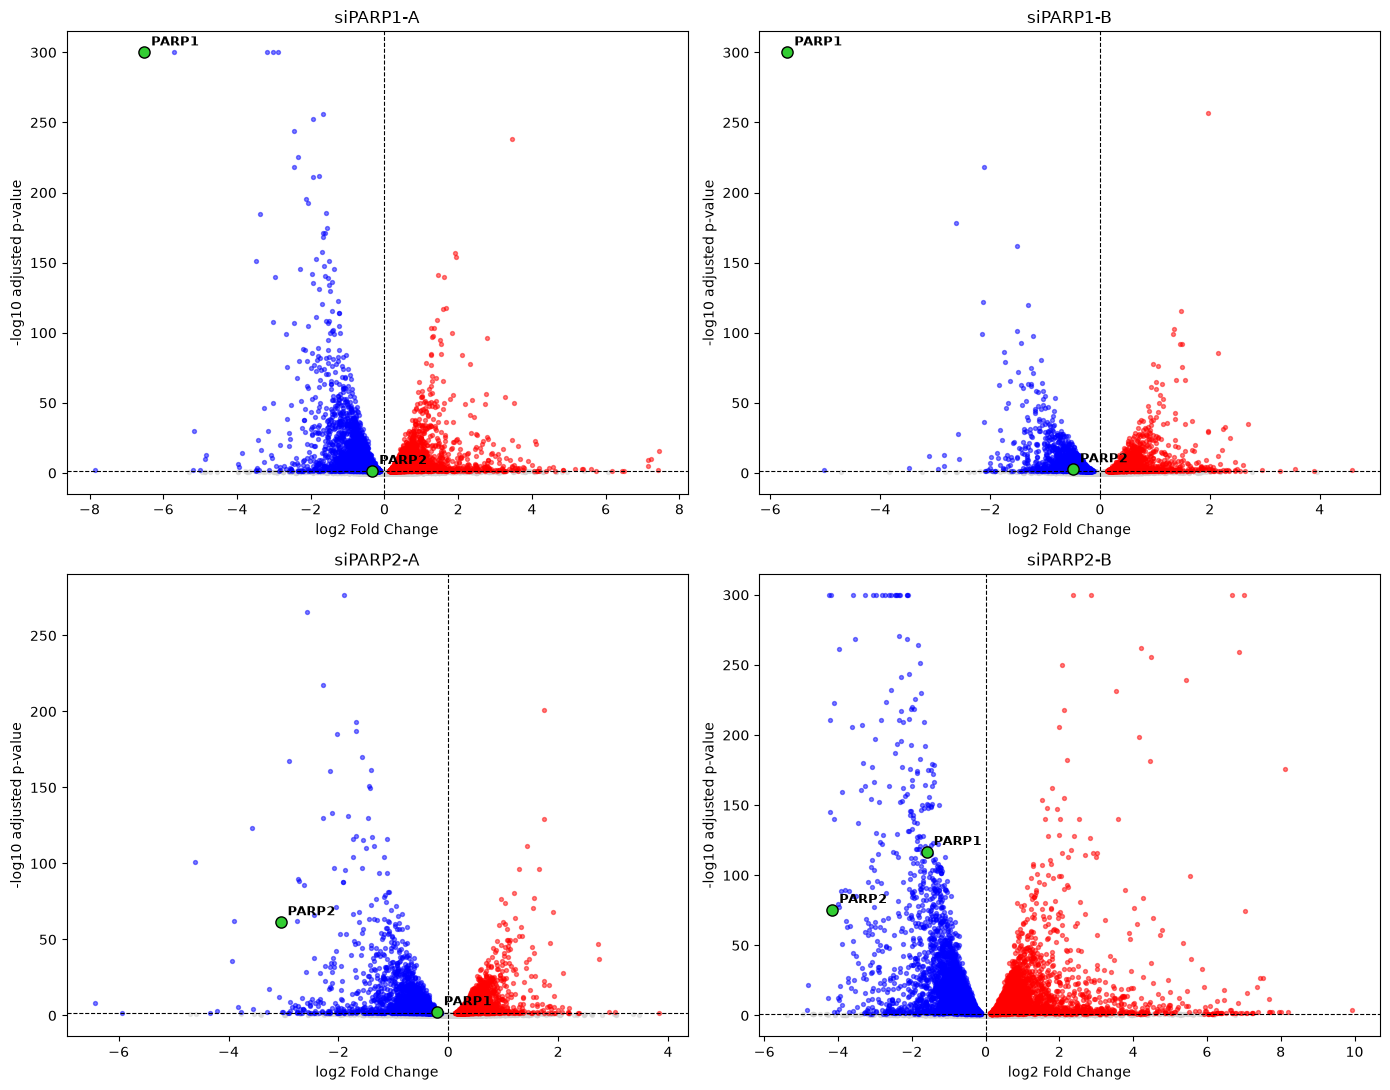

In [51]:
target_genes = {
    "PARP1": "ENSG00000143799",
    "PARP2": "ENSG00000129484"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()

for ax, (treatment, results) in zip(axes, stat_results.items()):

    plot_data = results.dropna(
        subset=["log2FoldChange", "padj"]
    ).copy()

    plot_data["neg_log10_padj"] = -np.log10(
        plot_data["padj"].clip(lower=1e-300)
    )

    significant = plot_data["padj"] < 0.05
    upregulated = significant & (plot_data["log2FoldChange"] > 0)
    downregulated = significant & (plot_data["log2FoldChange"] < 0)
    not_significant = ~significant

    # Background genes
    ax.scatter(
        plot_data.loc[not_significant, "log2FoldChange"],
        plot_data.loc[not_significant, "neg_log10_padj"],
        color="lightgrey", s=8, alpha=0.5
    )

    ax.scatter(
        plot_data.loc[upregulated, "log2FoldChange"],
        plot_data.loc[upregulated, "neg_log10_padj"],
        color="red", s=8, alpha=0.5
    )

    ax.scatter(
        plot_data.loc[downregulated, "log2FoldChange"],
        plot_data.loc[downregulated, "neg_log10_padj"],
        color="blue", s=8, alpha=0.5
    )

    # Highlight PARP1 and PARP2
    for gene, ensembl_id in target_genes.items():

        if ensembl_id in plot_data.index:
            gene_data = plot_data.loc[ensembl_id]

            ax.scatter(
                gene_data["log2FoldChange"],
                gene_data["neg_log10_padj"],
                color="limegreen",
                edgecolor="black",
                s=65,
                zorder=5
            )

            ax.annotate(
                gene,
                (
                    gene_data["log2FoldChange"],
                    gene_data["neg_log10_padj"]
                ),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=9,
                fontweight="bold"
            )

    ax.axvline(0, linestyle="--", color="black", linewidth=0.8)
    ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=0.8)

    ax.set_title(treatment)
    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("-log10 adjusted p-value")

plt.tight_layout()
plt.show()

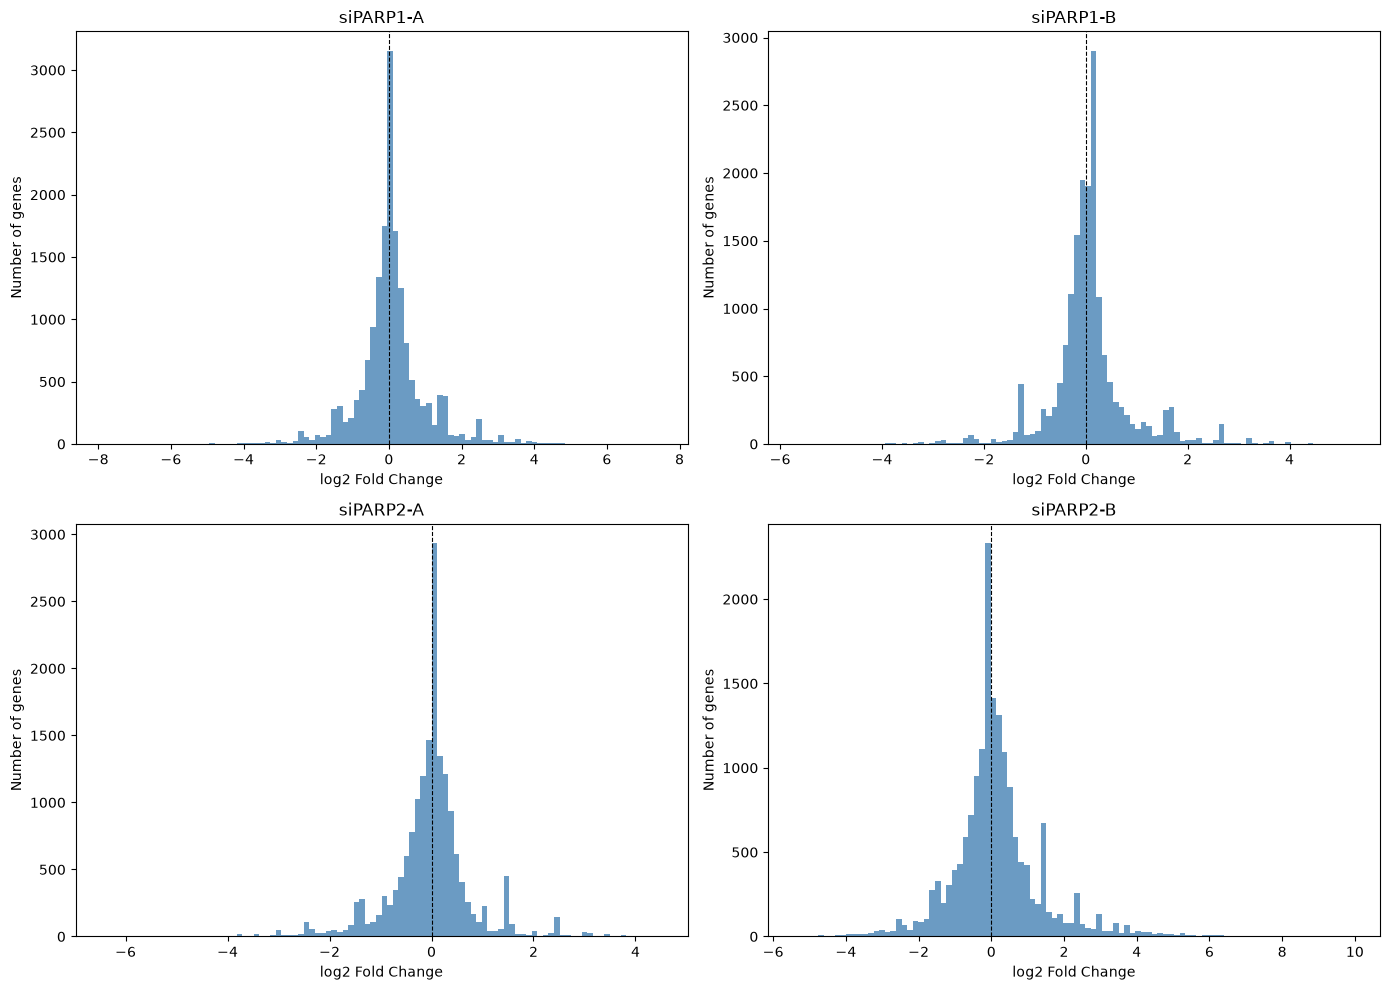

In [50]:
# Distribution of log2FC

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (treatment, results) in zip(axes, stat_results.items()):

    log2fc = results["log2FoldChange"].dropna()

    ax.hist(log2fc, bins=100, color="steelblue", alpha=0.8)
    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(treatment)
    ax.set_xlabel("log2 Fold Change")
    ax.set_ylabel("Number of genes")

plt.tight_layout()
plt.show()

## Interpretation of DGE visualisations

### 1. MA plot — Expression level vs. fold change

**Logic:** Plots the average expression level (`baseMean`) against the estimated log2 fold change for each gene.

**Learnings:**
- Lowly expressed genes show greater variability in their estimated fold changes.
- Highly expressed genes tend to cluster closer to zero, indicating more stable estimates.
- Most genes show relatively modest expression changes.

**Purpose:** Provides an overview of how expression level relates to the magnitude and variability of differential expression.

### 2. Volcano plot — Fold change vs. statistical significance

**Logic:** Plots the estimated log2 fold change against the negative log10-transformed p-value.

**Learnings:**
- Most genes cluster around log2FC = 0.
- A subset of genes shows stronger evidence of differential expression.
- Both upregulation and downregulation occur, with several strongly downregulated genes.

**Purpose:** Identifies genes with both substantial expression changes and statistical evidence supporting those changes. The plotted threshold represents nominal significance; adjusted p-values are required to assess significance after multiple-testing correction.

### 3. log2FC distribution — Overall expression response

**Logic:** Shows the frequency distribution of estimated log2 fold changes across all genes with valid estimates.

**Learnings:**
- Most genes have log2FC values close to zero.
- The distribution has tails in both directions, representing genes with larger expression changes.
- The median is slightly negative, indicating a very small overall shift towards downregulation.

**Purpose:** Establishes the overall distribution of treatment-associated expression changes, providing the background against which seed-positive and seed-negative genes will subsequently be compared.

## Summary

### Differential expression analysis

- Prepared raw count data for 19,227 protein-coding genes across five conditions: siNC and four siRNA treatments.
- Used PyDESeq2 with a design formula of `~condition`, setting siNC as the reference condition.
- Estimated size factors, gene-wise dispersions, dispersion trend and MAP dispersions before fitting the model.
- Calculated Cook's distances and performed outlier refitting where applicable.
- Extracted differential expression results for each of the four treatment-versus-control contrasts.

### Results

- Obtained valid log2FC estimates for 17,240 genes in each contrast.
- Identified 3,936–7,806 significantly differentially expressed genes per treatment (adjusted p-value < 0.05).
- Confirmed strong on-target knockdown of PARP1 by siPARP1-A/B and PARP2 by siPARP2-A/B.
- Generated MA plots, volcano plots and log2FC distributions to inspect the overall expression responses.

### Limitations and considerations

- Each condition contains two biological replicates, limiting statistical power and the reliability of dispersion estimates.
- Differential expression results should therefore be interpreted with caution.
- All genes with valid log2FC estimates will be retained for the downstream seed analysis, irrespective of statistical significance.